# 05 · Clasificador No Basado en Árboles: Red Neuronal (MLP)

En este notebook se implementa y evalúa un método alternativo a los modelos basados en árboles de decisión (Decision Tree, Random Forest, LightGBM, XGBoost).

Se utiliza un **Perceptrón Multicapa (MLP - Multi-Layer Perceptron)**, una arquitectura de **Red Neuronal Artificial (ANN)** con capas densas y funciones de activación no lineales (ReLU). Este enfoque responde directamente al objetivo específico del proyecto:
> *"Implementar y comparar múltiples algoritmos de clasificación (árboles basados en ensambles, boosting y redes neuronales)."*

### Aspectos Clave de la Red Neuronal:
1. **Preprocesamiento Diferenciado:** Las redes neuronales son sensibles a la escala de las variables numéricas. Se utiliza el pipeline con imputación por mediana, compresión logarítmica con conservación de signo () y estandarización z-score ().
2. **Arquitectura:** 2 capas ocultas densas con 128 y 64 neuronas, activación ReLU, regularización L2 (), optimizador Adam y parada temprana ().
3. **Evaluación Integral:** Se evalúa en la partición de prueba oficial (415,658 flujos) tanto en clasificación binaria como multiclase.


> **Etapa III — cinco clases.** Desde la Etapa III, `src/data_loader.py` incluye además
> **DDoS MQTT** (MQTT Publish Flood, clase 3) y **DDoS ICMP** (ICMP flood, clase 4), con una
> muestra de hasta 200.000 flujos de cada uno. Las salidas guardadas en este notebook
> corresponden a la última ejecución; para reproducir los resultados de la Presentación 2
> (solo benigno, SYN y UDP), definir `NIDS_ATAQUES_NUEVOS=0` antes de abrir Jupyter.

In [1]:
import sys
import time
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ.resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import train_test_split

from src.data_loader import CARPETA_PROCESADOS, CARPETA_RESULTADOS, CLASES, cargar_procesado, cargar_variables
from src.features import preprocesador
from src.evaluate import configurar_graficos, metricas_binarias, metricas_multiclase

configurar_graficos()
SEMILLA = 42


## 1. Carga de Datos y Configuración


In [2]:
cfg = cargar_variables()
variables = cfg["variables"]

train = cargar_procesado("train")
val = cargar_procesado("val")
test = cargar_procesado("test")

print(f"Variables seleccionadas ({len(variables)}):", variables[:10], "...")
print(f"Registros -> Train: {len(train):,} | Val: {len(val):,} | Test: {len(test):,}")

MUESTRA_TRAIN = 100_000
muestra_train, _ = train_test_split(
    train, train_size=MUESTRA_TRAIN, stratify=train["clase"], random_state=SEMILLA
)
print(f"Muestra balanceada de entrenamiento para MLP: {len(muestra_train):,} registros")


Variables seleccionadas (35): ['Header_Length', 'Protocol Type', 'Duration', 'Rate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number'] ...
Registros -> Train: 660,724 | Val: 165,181 | Test: 624,074
Muestra balanceada de entrenamiento para MLP: 100,000 registros


## 2. Clasificación Binaria: Benigno vs Ataque DDoS


In [3]:
pipeline_bin = Pipeline([
    ("preprocesador", preprocesador(escalar=True)),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        solver="adam",
        alpha=0.001,
        batch_size=512,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=8,
        random_state=SEMILLA,
    ))
])

inicio = time.perf_counter()
pipeline_bin.fit(muestra_train[variables], muestra_train["etiqueta"])
t_train_bin = time.perf_counter() - inicio

pred_bin = pipeline_bin.predict(test[variables])
proba_bin = pipeline_bin.predict_proba(test[variables])[:, 1]
metricas_bin = metricas_binarias(test["etiqueta"], pred_bin, puntaje=proba_bin, clase_real=test["clase"])
pd.DataFrame([metricas_bin], index=["Red Neuronal (MLP)"]).T


,Red Neuronal (MLP)
Accuracy,0.987200
Precision DDoS,0.999990
Recall DDoS,0.986390
F1 DDoS,0.993143
F1 macro,0.948561
Tasa falsos positivos,0.000160
PR-AUC,0.999964
Recall SYN,0.997088
Recall UDP,0.999295
Recall MQTT,0.136050


## 3. Clasificación Multiclase: Benigno vs DDoS SYN vs DDoS UDP


In [4]:
pipeline_mul = Pipeline([
    ("preprocesador", preprocesador(escalar=True)),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        solver="adam",
        alpha=0.001,
        batch_size=512,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=8,
        random_state=SEMILLA,
    ))
])

inicio = time.perf_counter()
pipeline_mul.fit(muestra_train[variables], muestra_train["clase"])
t_train_mul = time.perf_counter() - inicio

pred_mul = pipeline_mul.predict(test[variables])
metricas_mul = metricas_multiclase(test["clase"], pred_mul)
pd.DataFrame([metricas_mul], index=["Red Neuronal (MLP)"]).T


,Red Neuronal (MLP)
Accuracy,0.989104
Precision macro,0.967118
Recall macro,0.854152
F1 macro,0.869128
Recall Benigno,0.999920
Recall DDoS SYN,0.996937
Recall DDoS UDP,0.999504
Recall DDoS MQTT,0.274715
Recall DDoS ICMP,0.999685
Tasa falsos positivos,0.000080


## 4. Matriz de Confusión Multiclase


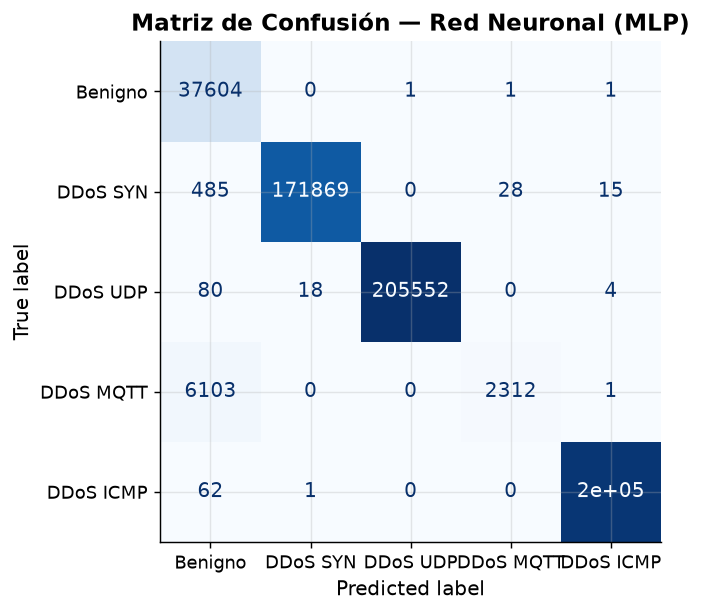

In [5]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    test["clase"],
    pred_mul,
    labels=sorted(CLASES),
    display_labels=[CLASES[c] for c in sorted(CLASES)],
    cmap="Blues",
    ax=ax,
    colorbar=False,
)
ax.set_title("Matriz de Confusión — Red Neuronal (MLP)")
plt.show()


## 5. Comparativa General: Red Neuronal vs Modelos de Árboles


In [6]:
comp_path = CARPETA_RESULTADOS / "comparacion_general_arboles_vs_mlp.csv"
if comp_path.exists():
    df_comp = pd.read_csv(comp_path).set_index("Modelo")
    display(df_comp)


,Accuracy,Precision macro,Recall macro,F1 macro,Recall Benigno,Recall DDoS SYN,Recall DDoS UDP,Tasa falsos positivos
Modelo,,,,,,,,
Regresión logística,0.998540,0.994805,0.998817,0.996791,0.999840,0.997111,0.999499,0.000160
Árbol de decisión,0.998342,0.994076,0.998637,0.996330,0.999734,0.996781,0.999397,0.000266
Random Forest,0.998530,0.994797,0.998849,0.996802,1.000000,0.997024,0.999523,0.000000
LightGBM,0.998761,0.995671,0.999034,0.997338,1.000000,0.997558,0.999543,0.000000
XGBoost,0.998787,0.995806,0.999054,0.997417,1.000000,0.997610,0.999553,0.000000
Red Neuronal (MLP),0.998463,0.994457,0.998782,0.996596,0.999920,0.997019,0.999407,0.000080


## Conclusiones

> Las cifras de estas conclusiones corresponden a la ejecución con tres clases (benigno, SYN y UDP), la que se presentó en la Presentación 2. Al ejecutar con cinco clases, comparar con las nuevas salidas y actualizarlas.

- En la **prueba oficial**, la MLP (128-64, ReLU, entrenada con una muestra
  estratificada de 100.000 flujos) logra F1 macro 0,9957 en binaria, con 3
  falsas alarmas y 590 ataques no detectados, y 0,9966 en multiclase.
- Queda al nivel de la regresión logística y por debajo de LightGBM
  (0,9967 binaria, 0 falsas alarmas, 456 ataques no detectados; 0,9973
  multiclase).
- Que una familia de modelos completamente distinta llegue al mismo nivel en la
  prueba oficial refuerza que la dificultad está en el cambio entre capturas y
  no en el algoritmo.
- La MLP necesita escalado, más ajuste y es menos interpretable, así que no se
  elige como modelo final.

> Nota: estas cifras corresponden a la partición original (entrenamiento,
> validación y prueba oficial separada). El script
> `src/aplicar_split_80_20.py` mezcla la prueba oficial con el entrenamiento y
> sobrescribe `data/processed/` y algunas tablas de `deliverables/resultados/`;
> esos resultados no son comparables con los de este notebook.
